# Exploration du corpus

4 982 exercices et huit tags non exclusifs. Les 2 304 exemples sans cible sont conservés, y compris les 41 listes initialement vides.

Ce notebook relit les effectifs du découpage de référence. Il n'entraîne aucun modèle et ne nécessite pas les JSON bruts. Il ne remplace pas une nouvelle exploration du texte si le corpus change.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/splits/split_summary.json").exists())
TAGS = json.loads((ROOT / "data/splits/split_summary.json").read_text(encoding="utf-8"))["target_order"]
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

## Données et contrôles

Source : `data/splits/split_summary.json`. Les supports sont descriptifs ; les statistiques de validation et test ne servent pas à ajuster un modèle.

In [2]:
summary = json.loads((ROOT / "data/splits/split_summary.json").read_text(encoding="utf-8"))
assert summary["target_order"] == TAGS
assert sum(part["records"] for part in summary["splits"].values()) == 4982
counts = pd.DataFrame([{ "ensemble": name, "exercices": values["records"],
                        "sans cible": values["without_target"]}
                      for name, values in summary["splits"].items()]).set_index("ensemble")
display(counts)

,exercices,sans cible
ensemble,,
train,2981,1382
validation,997,461
test,1004,461


## Répartition des tags

Les catégories se chevauchent : leurs supports ne s'additionnent pas au nombre d'exercices.

,train,validation,test
math,844,282,282
graphs,325,109,108
strings,253,85,84
number theory,210,70,70
trees,194,65,65
geometry,100,33,33
games,63,21,21
probabilities,55,19,18


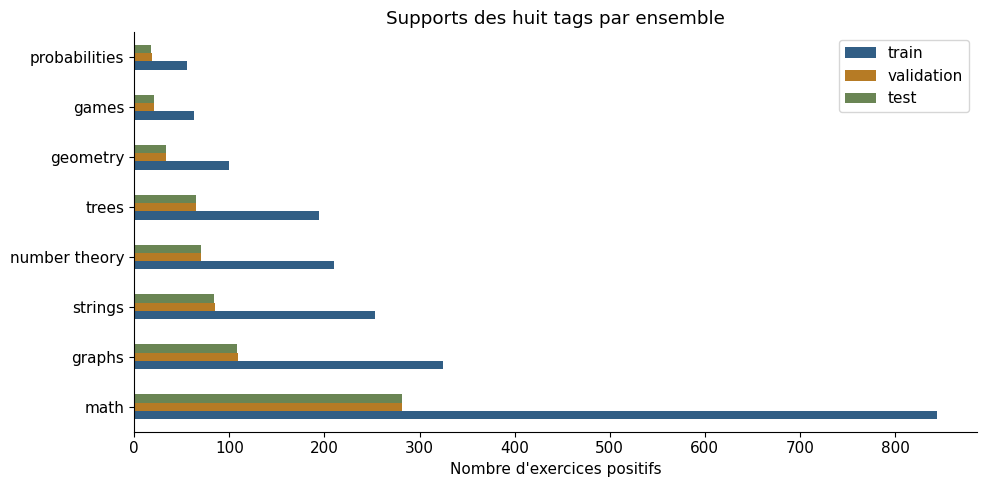

In [3]:
supports = pd.DataFrame({name: values["positive_counts"] for name, values in summary["splits"].items()}).reindex(TAGS)
display(supports)
ax = supports.plot.barh(color=["#315e85", "#b67b25", "#6a8554"])
ax.set_xlabel("Nombre d'exercices positifs")
ax.set_title("Supports des huit tags par ensemble")
ax.set_xlim(left=0)
plt.tight_layout()
plt.show()

Les classes `games` et `probabilities` sont rares : 21 et 19 positifs en validation. Une moyenne macro leur donne autant de poids qu'à `math`.

## Exemples sans cible

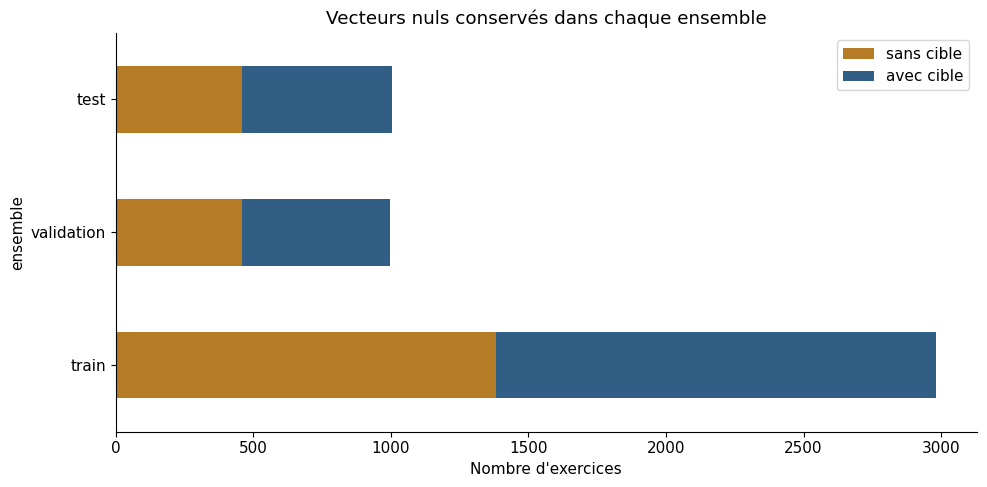

In [4]:
empty = counts[["sans cible"]].copy()
empty["avec cible"] = counts["exercices"] - empty["sans cible"]
assert int(empty["sans cible"].sum()) == 2304
ax = empty.plot.barh(stacked=True, color=["#b67b25", "#315e85"])
ax.set_xlabel("Nombre d'exercices")
ax.set_title("Vecteurs nuls conservés dans chaque ensemble")
ax.set_xlim(left=0)
plt.tight_layout()
plt.show()

## Conséquences pour l'évaluation

Une prédiction vide est légitime. L'exact match doit être accompagné de F1 par classe et de la fréquence des fausses alertes sur les exercices sans cible. Aucun tag supplémentaire n'est imposé au modèle.